In [1]:
import os
import urllib.request
import zipfile

os.makedirs("data", exist_ok=True)

url = "https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip"

zip_path = "data/dataset-resized.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Download completed!")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("data")

print("Dataset extracted successfully!")

Download completed!
Dataset extracted successfully!


In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Everything is ready!")

TensorFlow version: 2.21.0
GPU devices: []
Everything is ready!


In [3]:
print(os.listdir("data"))

['dataset-resized', 'dataset-resized.zip', '__MACOSX']


In [4]:
dataset_path = "data/dataset-resized"

categories = os.listdir(dataset_path)

print("Categories:", categories)

for category in categories:
    category_path = os.path.join(dataset_path, category)

    if os.path.isdir(category_path):
        images = os.listdir(category_path)
        print(category, ":", len(images), "images")

Categories: ['.DS_Store', 'cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
cardboard : 403 images
glass : 501 images
metal : 410 images
paper : 594 images
plastic : 482 images
trash : 137 images


In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

dataset_path = "data/dataset-resized"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 2527 files belonging to 6 classes.
Using 1769 files for training.
Found 2527 files belonging to 6 classes.
Using 758 files for validation.
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Number of classes: 6


In [7]:
n_batches = tf.data.experimental.cardinality(val_test_ds).numpy()

val_ds = val_test_ds.take(n_batches // 2)
test_ds = val_test_ds.skip(n_batches // 2)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 56
Validation batches: 12
Testing batches: 12


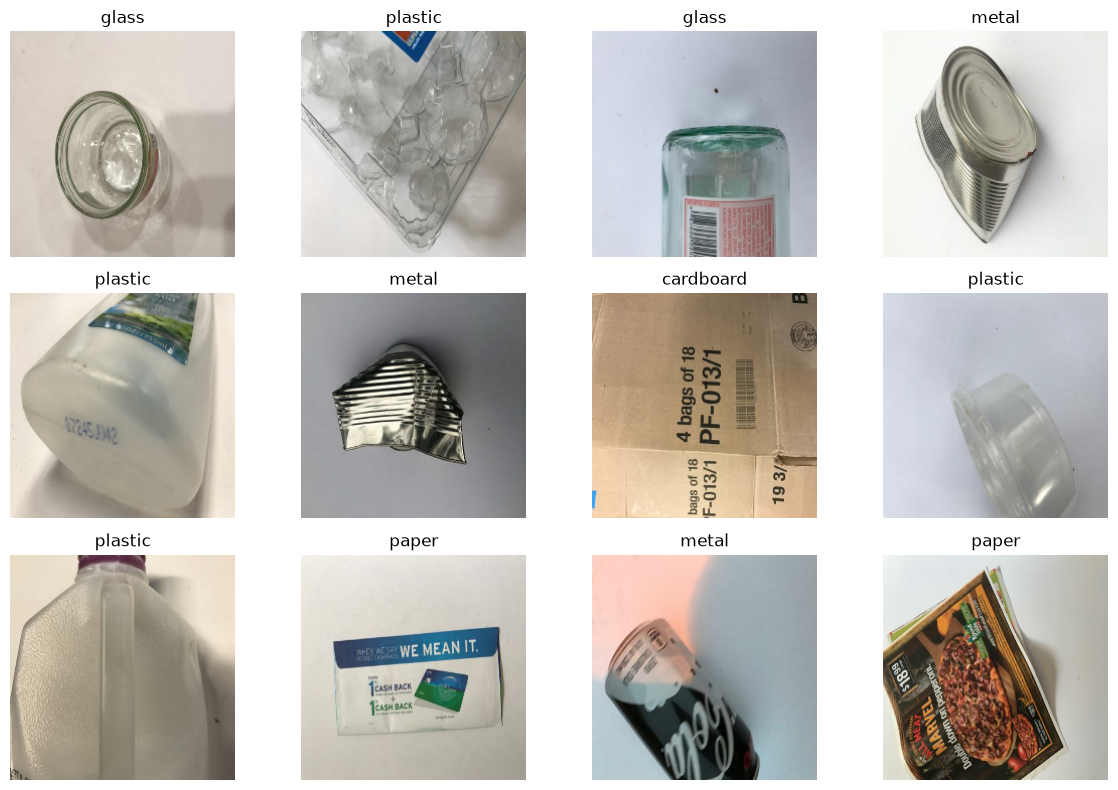

In [8]:
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [10]:
# Load MobileNetV2 without its original classification layer
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded!")
print("Total layers:", len(base_model.layers))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded!
Total layers: 154


In [11]:
# Data augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

# Build the complete model
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# MobileNetV2 preprocessing: pixel values from 0-255 to -1 to 1
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

# Extract features
x = base_model(x, training=False)

# Convert feature maps into a vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# Classify into six categories
outputs = tf.keras.layers.Dense(
    len(class_names),
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [15]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping]
)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 310ms/step - accuracy: 0.7354 - loss: 0.7128 - val_accuracy: 0.8021 - val_loss: 0.5809
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 324ms/step - accuracy: 0.7858 - loss: 0.5999 - val_accuracy: 0.7812 - val_loss: 0.5892
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 297ms/step - accuracy: 0.7937 - loss: 0.5529 - val_accuracy: 0.7839 - val_loss: 0.5753
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 19s 333ms/step - accuracy: 0.8089 - loss: 0.5038 - val_accuracy: 0.8229 - val_loss: 0.4924
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 300ms/step - accuracy: 0.8276 - loss: 0.4847 - val_accuracy: 0.8359 - val_loss: 0.4761
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 318ms/step - accuracy: 0.8214 - loss: 0.4678 - val_accuracy: 0.8307 - val_loss: 0.5344
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 317ms/step - accuracy: 0.8508 - loss: 0.4229 - val_accuracy: 0.7969 - val_loss: 0.5355
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 17s 307ms/step - accuracy: 0.8508 - loss: 0.4042 - val_accu

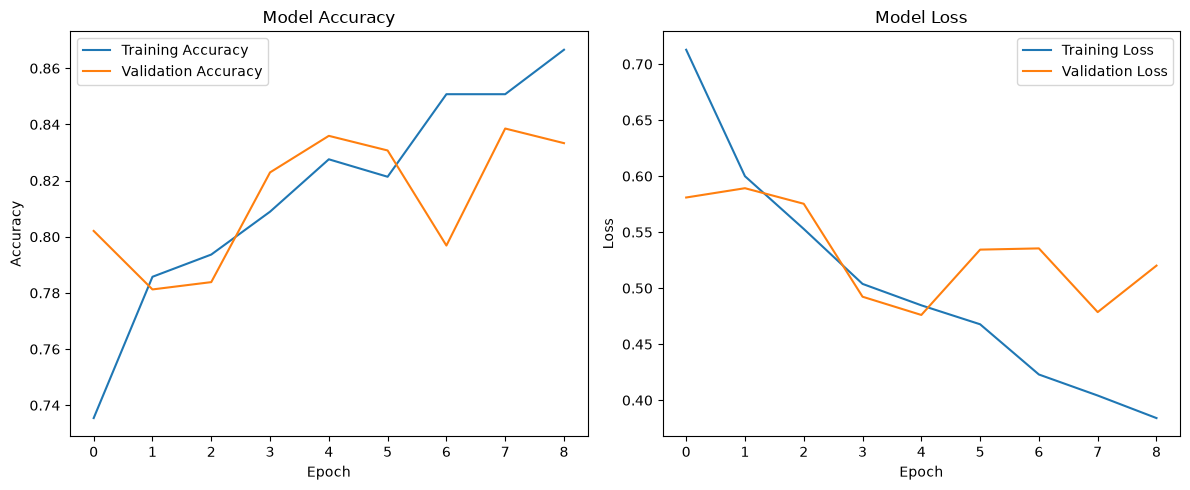

In [16]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [17]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step - accuracy: 0.8075 - loss: 0.4702
Test Loss: 0.47021985054016113
Test Accuracy: 80.74866533279419 %


In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

   cardboard       0.91      0.85      0.88        46
       glass       0.82      0.86      0.84        76
       metal       0.72      0.89      0.80        64
       paper       0.86      0.89      0.87        97
     plastic       0.86      0.68      0.76        71
       trash       0.65      0.55      0.59        20

    accuracy                           0.82       374
   macro avg       0.80      0.78      0.79       374
weighted avg       0.82      0.82      0.82       374



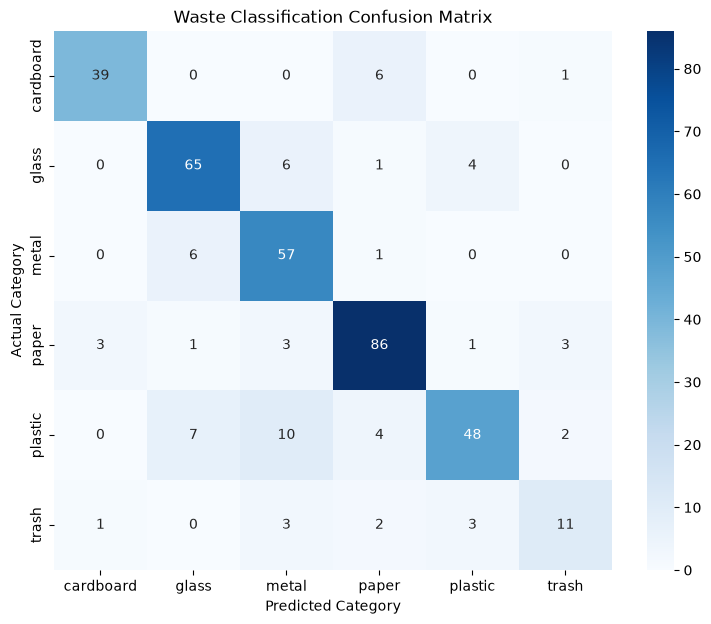

In [19]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Waste Classification Confusion Matrix")

plt.show()

In [23]:
from tensorflow.keras.utils import load_img, img_to_array

def predict_waste(image_path):

    img = load_img(image_path, target_size=(224, 224))

    img_array = img_to_array(img)

    img_array = np.expand_dims(img_array, axis=0)

    predictions = model.predict(img_array, verbose=0)[0]

    predicted_index = np.argmax(predictions)

    predicted_class = class_names[predicted_index]

    confidence = predictions[predicted_index] * 100

    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"Prediction: {predicted_class}\nConfidence: {confidence:.2f}%"
    )
    plt.show()

    return predicted_class, confidence

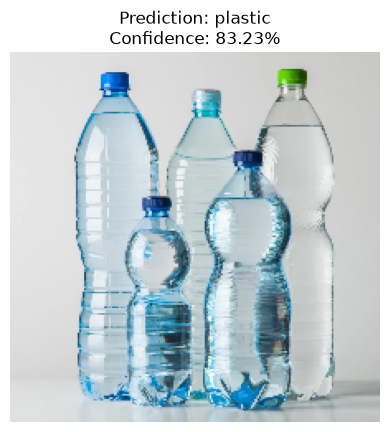

('plastic', np.float32(83.227615))

In [25]:
predict_waste("plastic-bottles.jpg")

In [26]:
model.save("waste_classification_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [27]:
loaded_model = tf.keras.models.load_model(
    "waste_classification_model.keras"
)